# **Credit Card Default Risk Prediction System**

- Financial institutions face significant losses due to **credit card defaults**, where customers fail to repay their dues on time. Identifying high-risk customers in advance is crucial for minimizing financial risk.
- Predict whether a credit card customer will default on their payment next month based on demographic and repayment history.

In [55]:
# importing python libraries for data Analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

- Loading dataset(CSV file).
-  dataset:https://drive.google.com/file/d/1xSYd7xZ5TAxYYG6_eP0ukCj97Hr9jE2O/view?usp=sharing

In [56]:
df=pd.read_csv("/content/Credit Card Defaulter Prediction.csv")
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,F,University,Married,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,Y
1,2,120000,F,University,Single,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,Y
2,3,90000,F,University,Single,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,N
3,4,50000,F,University,Married,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,N
4,5,50000,M,University,Married,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,N


In [57]:
df.shape

(30000, 25)

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         30000 non-null  int64 
 1   LIMIT_BAL  30000 non-null  int64 
 2   SEX        30000 non-null  object
 3   EDUCATION  30000 non-null  object
 4   MARRIAGE   30000 non-null  object
 5   AGE        30000 non-null  int64 
 6   PAY_0      30000 non-null  int64 
 7   PAY_2      30000 non-null  int64 
 8   PAY_3      30000 non-null  int64 
 9   PAY_4      30000 non-null  int64 
 10  PAY_5      30000 non-null  int64 
 11  PAY_6      30000 non-null  int64 
 12  BILL_AMT1  30000 non-null  int64 
 13  BILL_AMT2  30000 non-null  int64 
 14  BILL_AMT3  30000 non-null  int64 
 15  BILL_AMT4  30000 non-null  int64 
 16  BILL_AMT5  30000 non-null  int64 
 17  BILL_AMT6  30000 non-null  int64 
 18  PAY_AMT1   30000 non-null  int64 
 19  PAY_AMT2   30000 non-null  int64 
 20  PAY_AMT3   30000 non-null  i

- The dataset contains 30,000 rows and 25 columns.
- All 25 columns have 30,000 non-null values, indicating no missing values.
- feature Categories:
  - Identifier: ID
  - Demographics: LIMIT_BAL,SEX (M/F), EDUCATION, MARRIAGE, AGE
  - Repayment Status: PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6   
  - Bill Amounts: BILL_AMT1 to BILL_AMT6   
  - Payment Amounts: PAY_AMT1 to PAY_AMT6

**Repayment status (PAY_0, PAY_2 to PAY_6)**

- It shows how late the customer was in repaying in a given month.
PAY_0 is the most recent month, and PAY_6 is the oldest (the numbering follows the project brief; there is no PAY_1).
- Values: -1 = paid on time, 1 = payment delayed 1 month, 2 = delayed 2 months, and so on up to 9.
- Your brief lists only -1 and the delays. The original dataset also uses 0 and -2, which the brief doesn’t define, so check the value counts in your file and state in your report how you treated them.
Higher values mean worse repayment behavior, so this is the strongest risk signal.

**Bill amounts (BILL_AMT1 to BILL_AMT6)**

- The amount of the credit card statement (what the customer owes) for each of the past 6 months.
- BILL_AMT1 is the most recent month, and BILL_AMT6 is the oldest.
A bill that keeps growing, or sits close to LIMIT_BAL, suggests the customer is stretched.
- Negative values can appear when the customer overpaid.

**Payment amounts (PAY_AMT1 to PAY_AMT6)**

- The amount the customer actually paid in each of the past 6 months.
PAY_AMT1 is the most recent month, and PAY_AMT6 is the oldest.
- Compare it with the bill: paying far less than the bill means the balance is carrying over.


**Bill = what is owed, payment amount = what was paid, repayment status = how late the payment was.**

In [59]:
df.dtypes.value_counts()

,count
int64,21
object,4


- There are 21 numerical (int64) columns and 4 categorical (object) columns.

In [60]:
df=df.drop(columns=["ID"])

- The ID column was identified as an identifier column. Since it uniquely identifies each customer and does not provide meaningful information for predicting the target variable(Not predictive feature), it was removed from the dataset.

In [61]:
df.rename(columns={'PAY_0': 'PAY_1'}, inplace=True)

- Treat **PAY_0 as PAY_1**.

In [62]:
df.columns=df.columns.str.strip().str.lower()
print(df.columns)

Index(['limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_1', 'pay_2',
       'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2',
       'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6', 'default'],
      dtype='object')


In [63]:
df.describe()

,limit_bal,age,pay_1,pay_2,pay_3,pay_4,pay_5,pay_6,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000
mean,167484.322667,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,49179.075167,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567
std,129747.661567,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,71173.768783,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775
min,10000.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000
25%,50000.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,2984.750000,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000
50%,140000.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,21200.000000,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000
75%,240000.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,64006.250000,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000
max,1000000.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,983931.000000,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000


In [64]:
df.describe(include="object")

,sex,education,marriage,default
count,30000,30000,30000,30000
unique,2,6,4,2
top,F,University,Single,N
freq,18112,14030,15964,23364


- **sex** has 2 unique categories, **education** has 6, **marriage** has 4, and default has 2 categories.
- The most frequent categories are F in **sex**, University in **education**, Single in **marriage**, and N in **default**.

limit_bal    0
sex          0
education    0
marriage     0
age          0
pay_1        0
pay_2        0
pay_3        0
pay_4        0
pay_5        0
pay_6        0
bill_amt1    0
bill_amt2    0
bill_amt3    0
bill_amt4    0
bill_amt5    0
bill_amt6    0
pay_amt1     0
pay_amt2     0
pay_amt3     0
pay_amt4     0
pay_amt5     0
pay_amt6     0
default      0
dtype: int64


<Axes: >

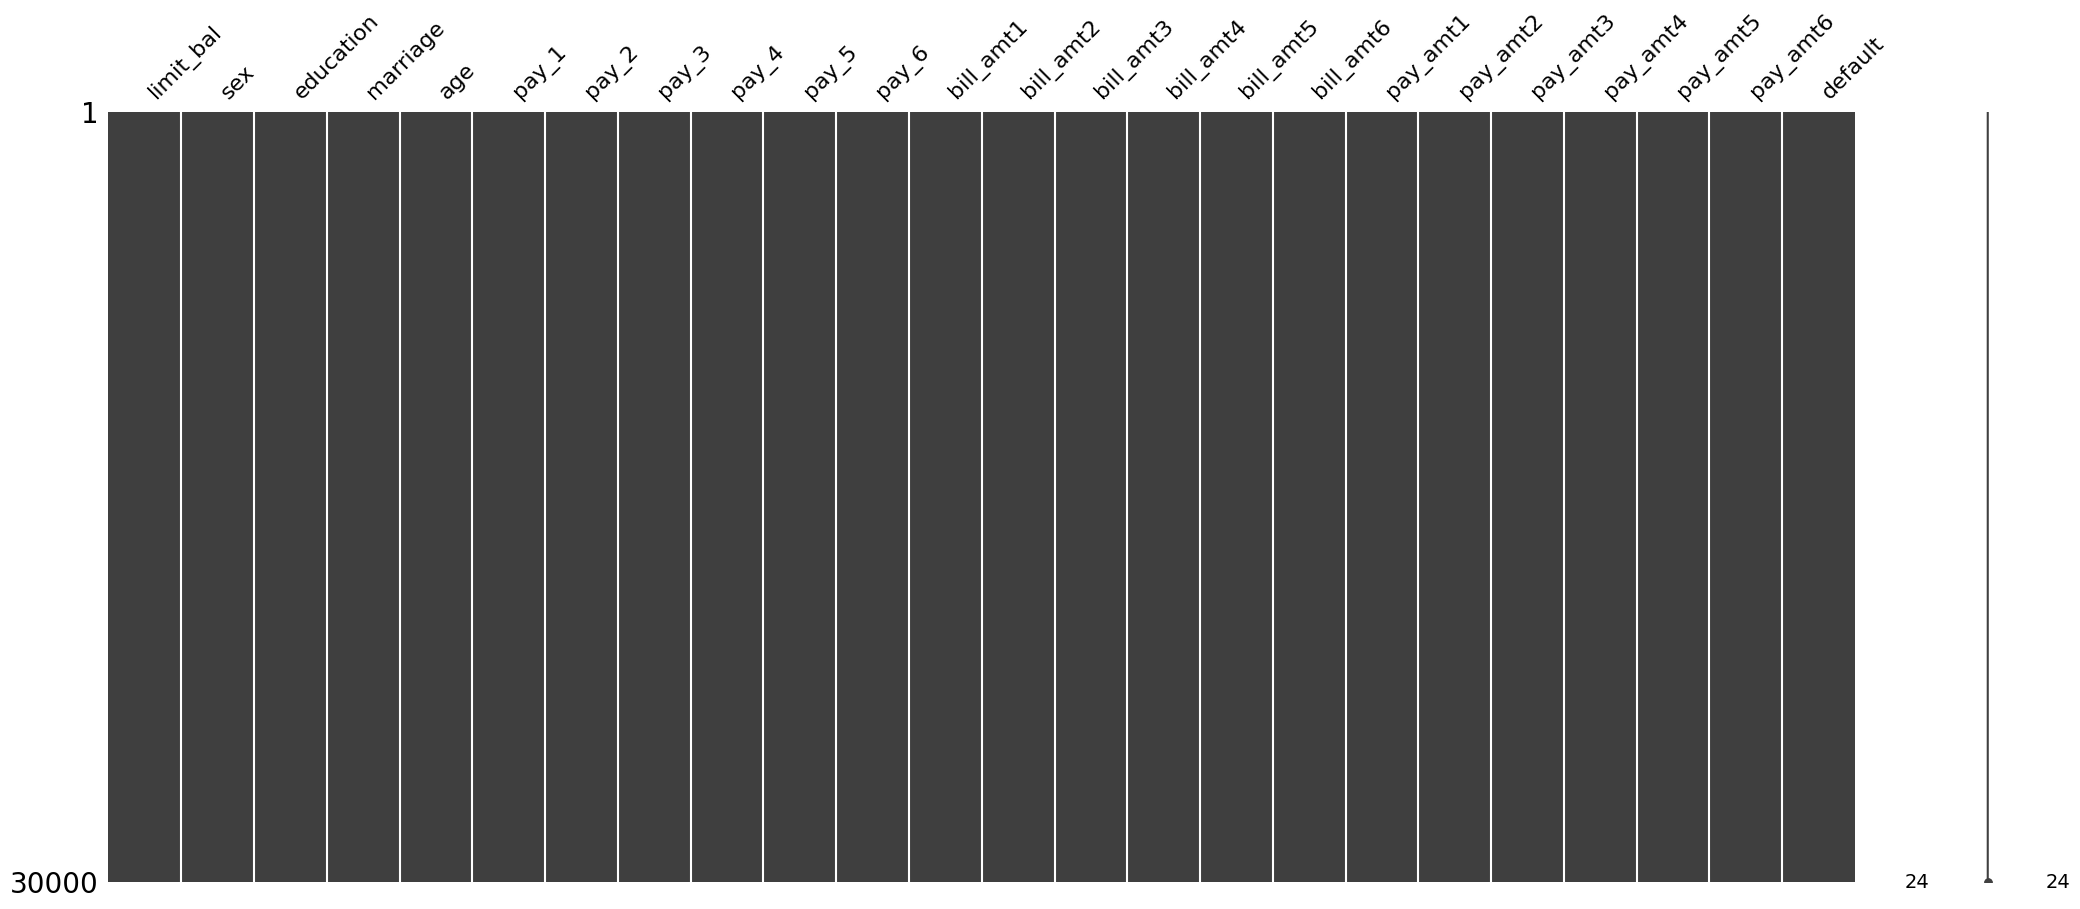

In [65]:
print(df.isnull().sum())
import missingno as msno
msno.matrix(df)

- No null values.

In [66]:
#checking duplicates
df.duplicated().sum()

np.int64(35)

- The dataset contains 35 duplicate rows.

In [67]:
df=df.drop_duplicates()
df.shape

(29965, 24)

- Duplicate rows were removed, Now total rows are **29965**

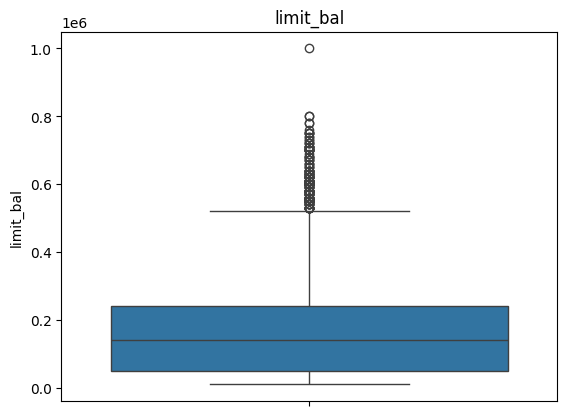

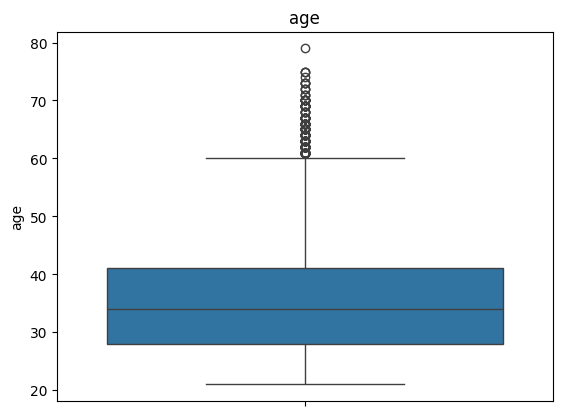

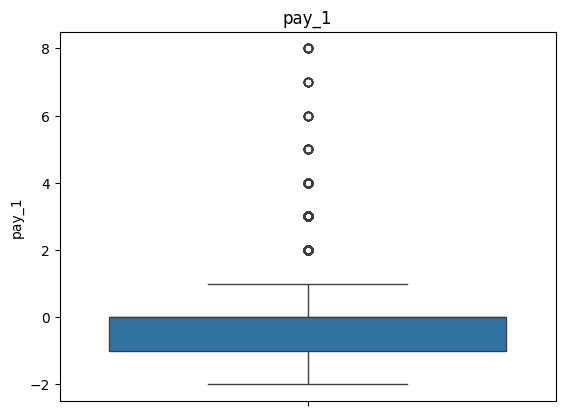

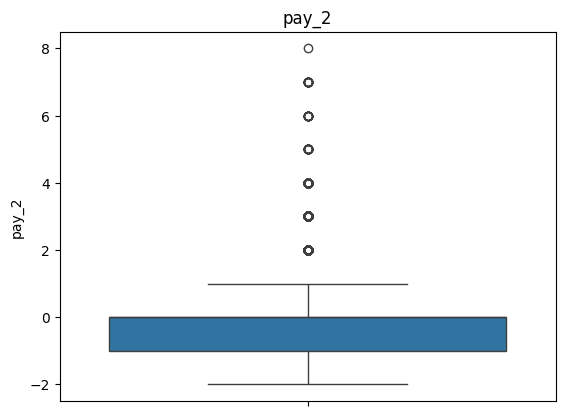

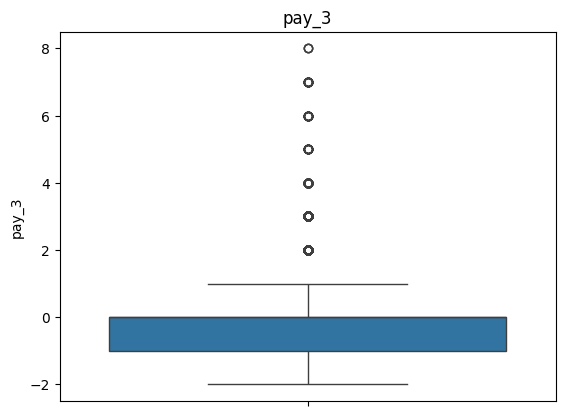

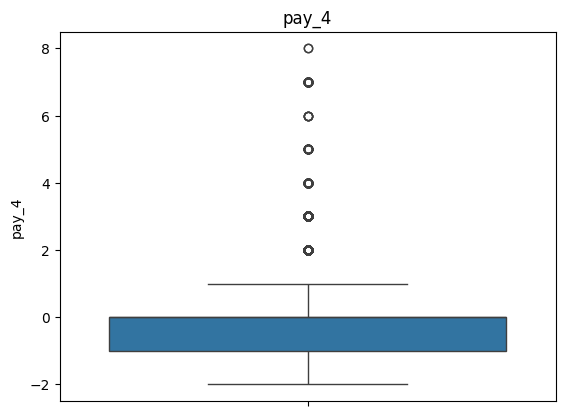

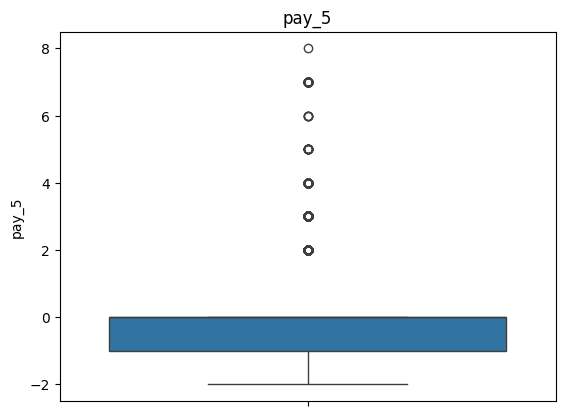

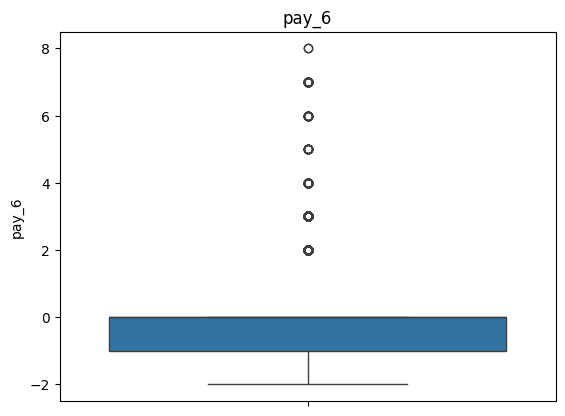

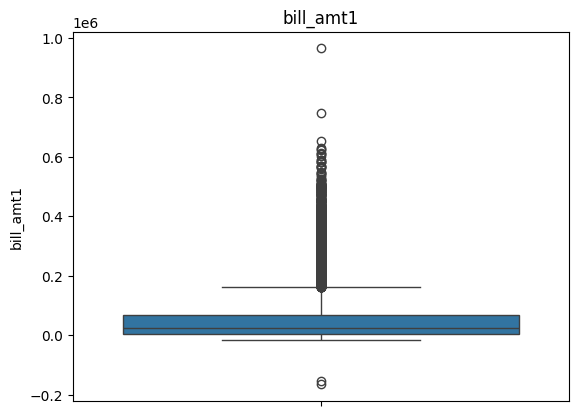

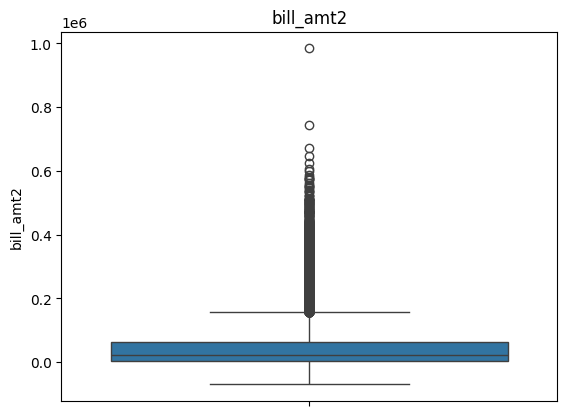

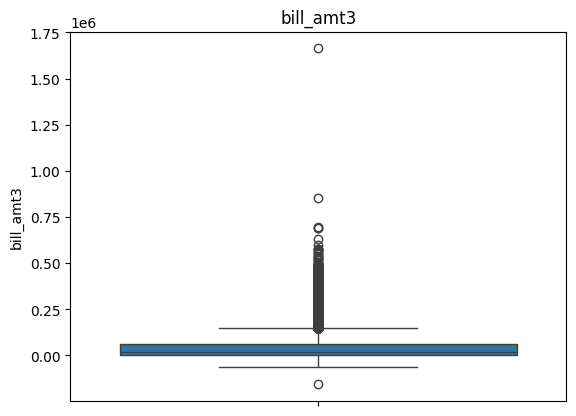

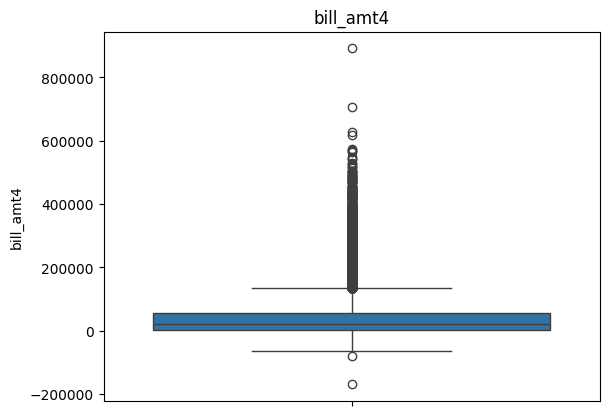

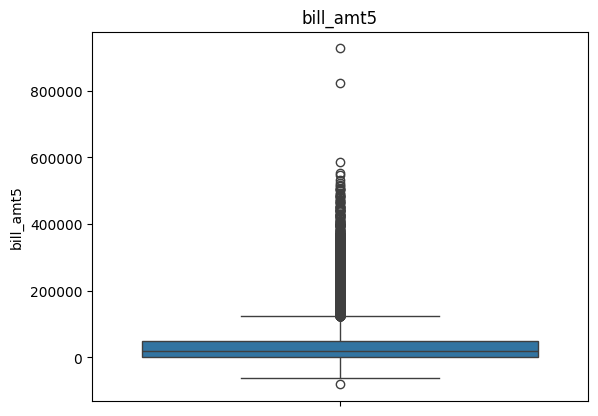

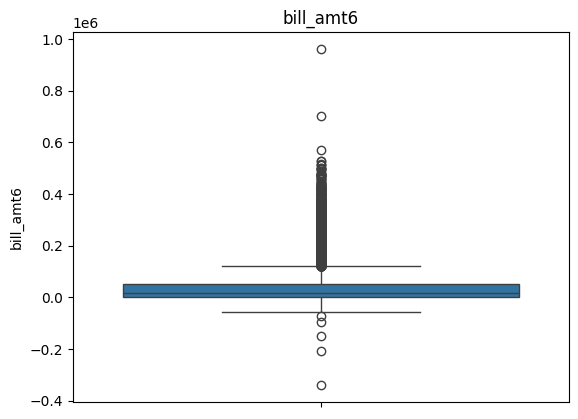

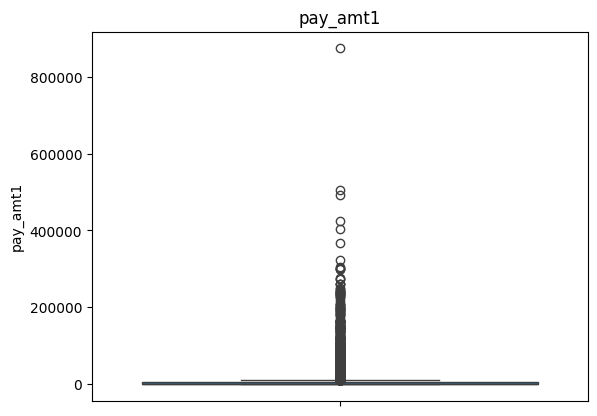

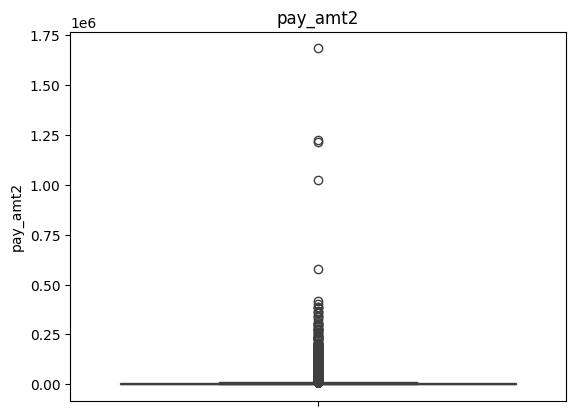

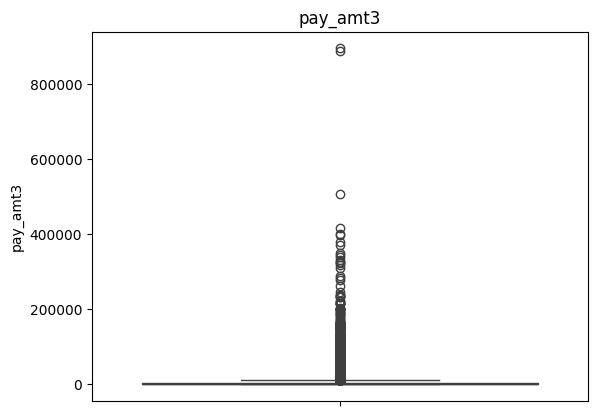

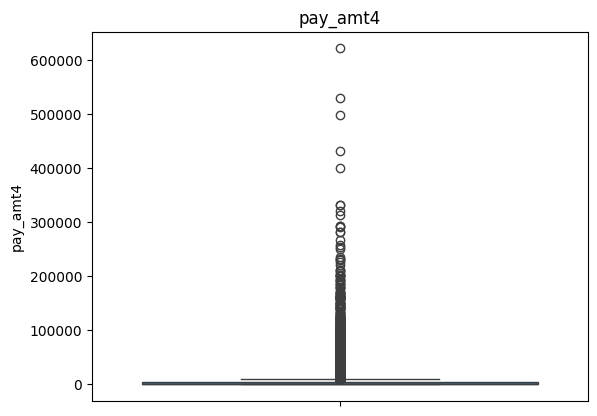

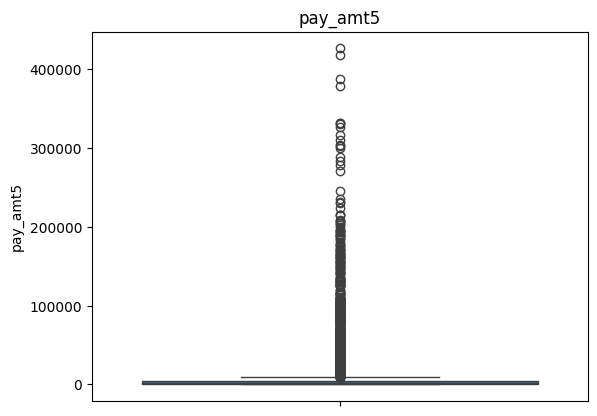

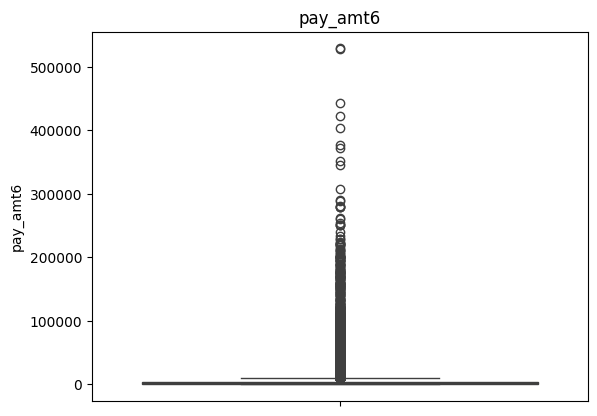

In [68]:
#finding outliers
for i in df.select_dtypes(include="number").columns:
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()

- **limit_bal**, **bill_amt1**-**bill_amt6**, and **pay_amt1**-**pay_amt6** show strong right-skewed distributions with extreme high values.
- **age** has comparatively fewer outliers, mainly at the higher age range.

In [69]:
df.select_dtypes(include="number").skew()

,0
limit_bal,0.993491
age,0.732056
pay_1,0.734606
pay_2,0.792070
pay_3,0.841464
pay_4,1.000799
pay_5,1.009329
pay_6,0.948609
bill_amt1,2.662513
bill_amt2,2.703862


In [70]:
# import seaborn as sns
# import matplotlib.pyplot as plt

# sns.pairplot(
#     df,
#     hue="default",
#     diag_kind="hist"
# )
# plt.show()

In [71]:
df["default"].value_counts()/len(df)*100

,count
default,
N,77.874187
Y,22.125813


In [72]:
df["Default"] = df["default"].astype(str).str.lower().map({"y": 1, "n": 0})

- converting target feature into binary

## **Train Test Split**

In [73]:
y=df["Default"]
X=df.drop(columns=["default","Default"])

print(X.shape)
print(y.shape)

(29965, 23)
(29965,)


- The dataset was divided into independent features (X) and the target variable (y). The **default** column was selected as the target variable and removed from X.

In [74]:
X.head()

,limit_bal,sex,education,marriage,age,pay_1,pay_2,pay_3,pay_4,pay_5,...,bill_amt3,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6
0,20000,F,University,Married,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,F,University,Single,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,F,University,Single,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,F,University,Married,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,M,University,Married,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [75]:
y.head()

,Default
0,1
1,1
2,0
3,0
4,0


In [76]:
# lets split the dataset into train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(23972, 23)
(23972,)
(5993, 23)
(5993,)


## **Feature Selection**

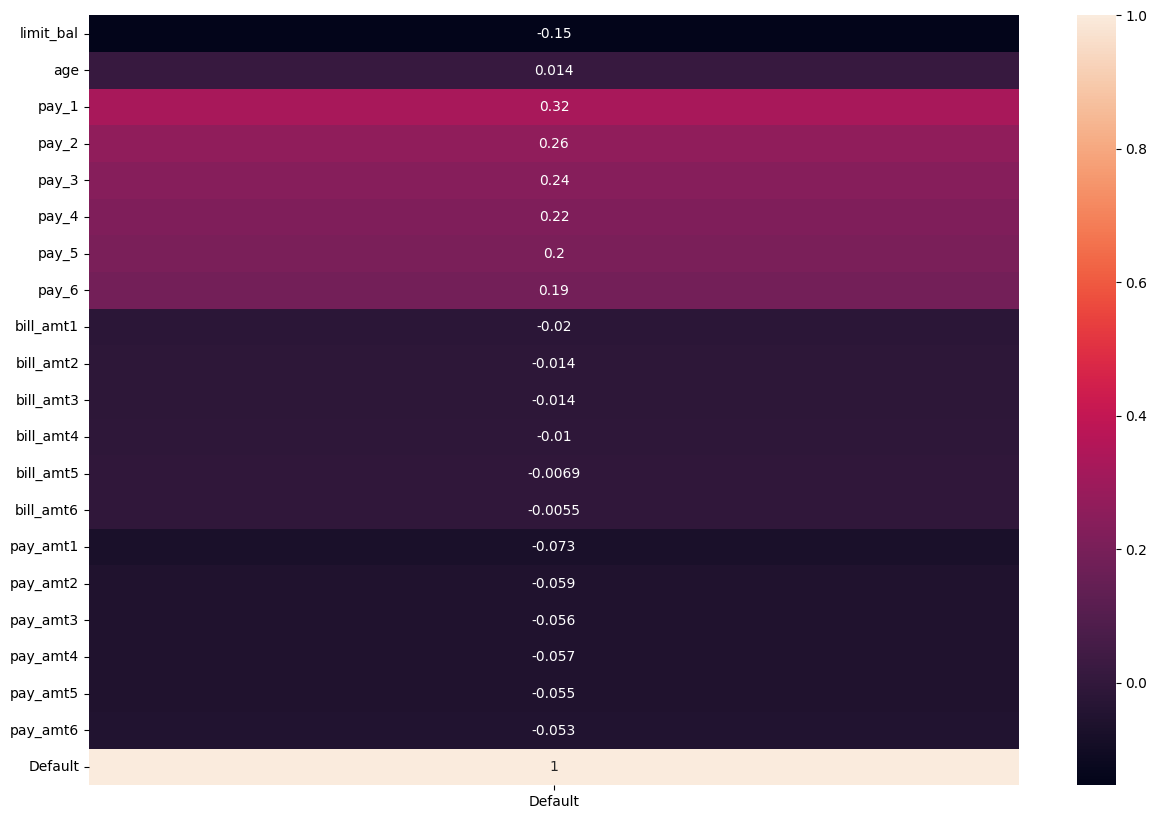

In [77]:
import seaborn as sns
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(numeric_only=True)[["Default"]],annot=True)
plt.show()

In [78]:
from scipy.spatial import transform
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder,StandardScaler

ct=ColumnTransformer(transformers=[("t1",OrdinalEncoder(),[1,2,3]),("t2",StandardScaler(),[0,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22])])
X_train_trans=ct.fit_transform(X_train)
X_train_trans=pd.DataFrame(X_train_trans)


mutual_info=mutual_info_classif(X_train_trans,y_train)

mutual_info=pd.Series(mutual_info)
mutual_info.index=X_train.columns
mutual_info.sort_values(ascending=True)

,0
education,0.000165
limit_bal,0.001643
age,0.002620
bill_amt5,0.004748
bill_amt4,0.005126
bill_amt6,0.006160
bill_amt3,0.006742
bill_amt2,0.008379
sex,0.009645
bill_amt1,0.010760


In [79]:
from sklearn.feature_selection import chi2
from sklearn.feature_selection import SelectKBest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder,MinMaxScaler

ct=ColumnTransformer(transformers=[("t1",OrdinalEncoder(),[1,2,3]),("t2",MinMaxScaler(),[0,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22])])
X_train_trans=ct.fit_transform(X_train)
X_train_trans=pd.DataFrame(X_train_trans)

select_columns=SelectKBest(chi2,k=23)
best_features=select_columns.fit_transform(X_train_trans,y_train)

#to display best features names
selected_features=X_train.columns[select_columns.get_support()]
print(selected_features)

Index(['limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_1', 'pay_2',
       'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2',
       'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1',
       'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6'],
      dtype='object')


# **SVM**

In [81]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler,OrdinalEncoder
from sklearn.svm import SVC

ct=ColumnTransformer(transformers=[("t1",OrdinalEncoder(),[1,2,3]),("t2",RobustScaler(),[0,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22])])

svm_model=make_pipeline(ct,SVC(kernel='rbf', gamma='scale',class_weight="balanced"))
svm_model.fit(X_train,y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('t1', OrdinalEncoder(),
                                                  [1, 2, 3]),
                                                 ('t2', RobustScaler(),
                                                  [0, 4, 5, 6, 7, 8, 9, 10, 11,
                                                   12, 13, 14, 15, 16, 17, 18,
                                                   19, 20, 21, 22])])),
                ('svc', SVC(class_weight='balanced'))])

- Most algorithms in scikit-learn (like Logistic Regression, Random Forest, and **SVM**) have a built-in parameter to handle imbalance automatically.

In [82]:
y_pred=svm_model.predict(X_test)

In [83]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.7870849324211581

In [84]:
#lets validate the model using confusion matrix
from sklearn.metrics import confusion_matrix,classification_report
cm=confusion_matrix(y_test,y_pred)
cm

array([[3991,  682],
       [ 594,  726]])

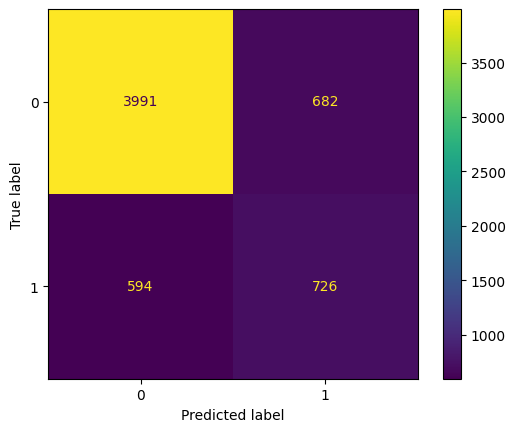

In [85]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.show()

In [86]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4673
           1       0.52      0.55      0.53      1320

    accuracy                           0.79      5993
   macro avg       0.69      0.70      0.70      5993
weighted avg       0.79      0.79      0.79      5993



- The SVC (Support Vector Classifier) is the best model overall for this dataset, primarily because it achieves the highest F1-Score (0.53) for the minority class (Class 1) without completely destroying your overall accuracy.

- 1. It actively fights the class imbalance: Both Naive Bayes and Logistic Regression suffer from "majority class blindness"—they simply guess Class 0 most of the time because it makes up roughly 78% of your data. SVC is the only model that managed to cross a 55% recall for Class 1, meaning it actually finds the minority cases.
- 2. Best structural balance: The F1-score is the harmonic mean of precision and recall. SVC’s Class 1 F1-score (0.53) beats Naive Bayes (0.48) and crushes Logistic Regression (0.35).

# **Make Prediction**

In [87]:
input_data=(50000,"M","University","Married",44,0,0,0,0,0,0,45335,46027,30286,26275,26823,27371,1524,1427,941,972,992,1000
)

#change the input_data into numpy array
input_data_as_numpy_array=np.asarray(input_data)

#reshape the array as we are p=redicting for one instance/row
input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)

prediction=svm_model.predict(input_data_reshaped)
print(prediction)

if prediction[0]==0:
  print("The Person is Not a Defaulter")
else:
  print("The Person is a Defaulter")

[0]
The Person is Not a Defaulter


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(


# **Saving the trained model**

In [88]:
import pickle

In [89]:
filename="default_trained_model.sav"
pickle.dump(svm_model, open(filename,"wb"))

In [90]:
#loading the saved model
default_loaded_model=pickle.load(open("/content/default_trained_model.sav","rb"))

In [91]:
input_data=(50000,"M","University","Married",44,0,0,0,0,0,0,45335,46027,30286,26275,26823,27371,1524,1427,941,972,992,1000
)

#change the input_data into numpy array
input_data_as_numpy_array=np.asarray(input_data)

#reshape the array as we are p=redicting for one instance/row
input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)

prediction=default_loaded_model.predict(input_data_reshaped)
print(prediction)

if prediction[0]==0:
  print("The Person is Not a Defaulter")
else:
  print("The Person is a Defaulter")

[0]
The Person is Not a Defaulter


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RobustScaler was fitted with feature names
  warnings.warn(
